<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Minería de Datos · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">BETO: revisión de los resultados del entrenamiento</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Miguel A. Garcia, Nadia Ramos, Ángel J. Zamora</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

**Dónde estamos.** `beto_entrenar.py` ajustó BETO (`dccuchile/bert-base-spanish-wwm-uncased`) 18 veces: 15 para las predicciones *out-of-fold* (5 folds agrupados por fuente × 3 semillas) y 3 con las 961 noticias para el test. Cada pieza se guardó en `resultados/beto_parciales/` y al final se juntaron en `beto_oof.csv` y `beto_test.csv`.

**Para dónde vamos.** Antes de usar esas probabilidades en `ensamble_beto.ipynb`, revisamos que los archivos estén completos y bien alineados, cuánto costó entrenar y qué tan estable es BETO entre semillas. **Este notebook no carga las etiquetas del test.**

## Contenido

* [Sección 0: Instalación y configuración](#seccion-0)
* [Sección 1: Verificación de los archivos](#seccion-1)
* [Sección 2: Costo del entrenamiento](#seccion-2)
* [Sección 3: Estabilidad entre semillas en CV](#seccion-3)
* [Sección 4: Conclusiones](#seccion-4)

<a id="seccion-0"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 0: Instalación y configuración</span></div>

> **Qué se hace:** instalamos los paquetes de BETO y cargamos las salidas del entrenamiento.
>
> **Qué se espera ver:** `torch` con CUDA, `transformers` y `accelerate` dentro del entorno `fakedes`.

**Instalación** (una sola vez, con el entorno `fakedes` activado). Los paquetes de BETO van en `requirements_beto.txt` y no en `environment.yml`:

```bash
pip install torch==2.11.0 --index-url https://download.pytorch.org/whl/cu128   # PyTorch con CUDA 12.8
pip install -r requirements_beto.txt
python -c "import torch; print(torch.cuda.is_available(), torch.cuda.get_device_name(0))"
```

**Entrenamiento** (desde la carpeta del repo; ≈ 1 h 15 min en una RTX 3050 Ti de 4 GB):

```bash
python beto_entrenar.py --prueba     # 1 época del fold 0 con la semilla 42: mide tiempo y memoria
python beto_entrenar.py              # los 18 entrenamientos; si se interrumpe, al relanzarlo salta lo que ya existe
```

En Linux conviene lanzarlo con `systemd-inhibit --what=sleep:idle:handle-lid-switch:handle-power-key python beto_entrenar.py`, para que la laptop no se suspenda ni se apague por accidente mientras entrena. El modelo se baja de Hugging Face sin cuenta ni token. No se guardan los pesos entrenados, solo las probabilidades.

### 0.1 Bibliotecas

In [1]:
# Manejo de datos
import os
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt

# Funciones compartidas del proyecto
import utils_fakedes as uf

### 0.2 Constantes y datos

In [2]:
SEMILLAS_BETO = [42, 43, 44]
uf.configurar_graficas()

corpus = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'corpus.parquet'), columns = ['id_unico', 'Category', 'fold_grupo'])
ids_test = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'test.parquet'), columns = ['id_unico'])['id_unico']   # solo ids, sin etiquetas
beto_oof = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'beto_oof.csv'))
beto_test = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'beto_test.csv'))
beto_log = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'beto_log.csv'), dtype = {'fold': str})
parciales = sorted(os.listdir(os.path.join(uf.RUTA_RESULTADOS, 'beto_parciales')))
print(f'beto_oof: {beto_oof.shape}; beto_test: {beto_test.shape}; bitácora: {len(beto_log)} renglones; piezas parciales: {len(parciales)}')

beto_oof: (961, 6); beto_test: (572, 5); bitácora: 18 renglones; piezas parciales: 18


<a id="seccion-1"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 1: Verificación de los archivos</span></div>

> **Qué se hace:** revisamos filas, ids, folds y valores faltantes.
>
> **Qué se espera ver:** 961 filas en `beto_oof.csv` con los mismos ids y folds que `corpus.parquet`, 572 en `beto_test.csv` con los ids de `test.parquet` y ningún NaN.

**Tabla 1.1.** Verificaciones.

In [3]:
def marca(condicion):
    '''
    Función que convierte una condición en ✅ o ❌

    inputs:
    --------
        condicion (bool): Resultado de la verificación

    outputs:
    --------
        str: '✅' si se cumple, '❌' si no
    '''
    return '✅' if condicion else '❌'

alineado = beto_oof.set_index('id_unico').loc[corpus['id_unico']]
n_nan = int(beto_oof.isna().sum().sum() + beto_test.isna().sum().sum())
promedio = beto_oof[['prob_s42', 'prob_s43', 'prob_s44']].mean(axis = 1)
filas = []
filas.append(('beto_oof.csv tiene 961 filas', len(beto_oof), marca(len(beto_oof) == 961)))
filas.append(('ids de beto_oof.csv = ids de corpus.parquet', int(beto_oof['id_unico'].isin(corpus['id_unico']).sum()), marca(set(beto_oof['id_unico']) == set(corpus['id_unico']))))
filas.append(('fold_grupo de beto_oof.csv = el de corpus.parquet', int((alineado['fold_grupo'].values == corpus['fold_grupo'].values).sum()),
              marca(bool((alineado['fold_grupo'].values == corpus['fold_grupo'].values).all()))))
filas.append(('beto_test.csv tiene 572 filas', len(beto_test), marca(len(beto_test) == 572)))
filas.append(('ids de beto_test.csv = ids de test.parquet', int(beto_test['id_unico'].isin(ids_test).sum()), marca(set(beto_test['id_unico']) == set(ids_test))))
filas.append(('NaN en los dos archivos', n_nan, marca(n_nan == 0)))
filas.append(('prob_beto = promedio de las 3 semillas', round(float(np.abs(promedio - beto_oof['prob_beto']).max()), 6), marca(bool(np.allclose(promedio, beto_oof['prob_beto'])))))
filas.append(('18 piezas parciales y 18 renglones de bitácora', f'{len(parciales)} y {len(beto_log)}', marca(len(parciales) == 18 and len(beto_log) == 18)))
pd.DataFrame(filas, columns = ['verificación', 'obtenido', 'estado'])

,verificación,obtenido,estado
0,beto_oof.csv tiene 961 filas,961,✅
1,ids de beto_oof.csv = ids de corpus.parquet,961,✅
2,fold_grupo de beto_oof.csv = el de corpus.parquet,961,✅
3,beto_test.csv tiene 572 filas,572,✅
4,ids de beto_test.csv = ids de test.parquet,572,✅
5,NaN en los dos archivos,0,✅
6,prob_beto = promedio de las 3 semillas,0.0,✅
7,18 piezas parciales y 18 renglones de bitácora,18 y 18,✅


<a id="seccion-2"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 2: Costo del entrenamiento</span></div>

> **Qué se hace:** resumimos minutos, memoria de GPU y pérdida final de cada entrenamiento.
>
> **Qué se espera ver:** cada entrenamiento de 4 épocas en unos minutos y la memoria por debajo de los 4 GB de la tarjeta.

**GPU y CPU.** BETO entrena en la GPU (NVIDIA RTX 3050 Ti de laptop, 4 GB), pero la CPU le prepara cada lote y le manda las operaciones. Por eso los minutos suben un poco cuando la CPU está ocupada con otra cosa: durante esta corrida se ejecutó en paralelo una prueba de `ensamble_beto.ipynb` (que usa CPU) y los entrenamientos pasaron de ≈ 3.3 a ≈ 4.3 min. Eso no cambia los resultados, solo el tiempo.

**Incidente.** A las 19:32 del 26 de noviembre se presionó el botón de encendido y la laptop se apagó con 13 de las 18 piezas guardadas. Se relanzó el script: saltó las 13 existentes y entrenó las 5 restantes. Cada pieza fija su semilla al empezar y su renglón de bitácora se escribe solo al terminar, así que no hay piezas a medias ni renglones repetidos.

**Tabla 2.1.** Bitácora de los 18 entrenamientos.

In [4]:
print(f'Total: {beto_log["minutos"].sum():.0f} min; por entrenamiento: {beto_log["minutos"].min():.1f} a {beto_log["minutos"].max():.1f} min; '
      f'memoria máxima: {beto_log["memoria_max_gb"].max():.2f} GB')
beto_log.round(3)

Total: 75 min; por entrenamiento: 3.3 a 5.3 min; memoria máxima: 2.09 GB


,fold,semilla,minutos,perdida_final,memoria_max_gb,perdida_epoca_1,perdida_epoca_2,perdida_epoca_3,perdida_epoca_4
0,0,42,3.32,0.087,2.082,0.538,0.282,0.152,0.087
1,1,42,3.58,0.090,2.083,0.517,0.292,0.169,0.090
2,2,42,3.95,0.068,2.083,0.535,0.239,0.125,0.068
3,3,42,4.06,0.082,2.085,0.507,0.268,0.139,0.082
4,4,42,4.12,0.078,2.085,0.515,0.270,0.136,0.078
5,0,43,3.98,0.062,2.082,0.572,0.290,0.122,0.062
6,1,43,4.16,0.112,2.085,0.560,0.321,0.180,0.112
7,2,43,4.35,0.081,2.085,0.536,0.258,0.157,0.081
8,3,43,4.36,0.078,2.084,0.527,0.271,0.145,0.078
9,4,43,4.44,0.078,2.082,0.544,0.272,0.143,0.078


**Figura 2.1.** Pérdida de entrenamiento por época (cada línea es un fold con una semilla).

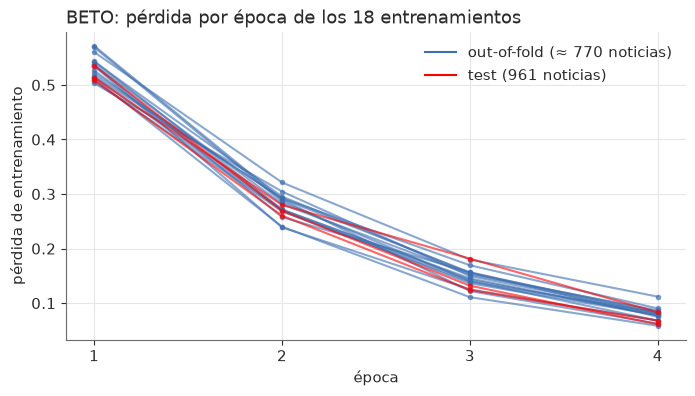

In [5]:
fig, ax = plt.subplots(figsize = (8, 4))
for i in range(len(beto_log)):
    fila = beto_log.iloc[i]
    perdidas = [fila['perdida_epoca_1'], fila['perdida_epoca_2'], fila['perdida_epoca_3'], fila['perdida_epoca_4']]
    color = 'red' if fila['fold'] == 'test' else '#3D6FB0'
    ax.plot([1, 2, 3, 4], perdidas, color = color, alpha = 0.6, marker = 'o', markersize = 3)
ax.plot([], [], color = '#3D6FB0', label = 'out-of-fold (≈ 770 noticias)')
ax.plot([], [], color = 'red', label = 'test (961 noticias)')
ax.set_xticks([1, 2, 3, 4])
ax.set_xlabel('época')
ax.set_ylabel('pérdida de entrenamiento')
ax.set_title('BETO: pérdida por época de los 18 entrenamientos')
ax.legend()
plt.show()

<a id="seccion-3"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 3: Estabilidad entre semillas en CV</span></div>

> **Qué se hace:** calculamos la F1 de fake *out-of-fold* de cada semilla por fold y la correlación entre semillas.
>
> **Qué se espera ver:** diferencias entre semillas menores de 0.10 por fold (umbral de la tarea) y una ganancia al promediar.

**Tabla 3.1.** F1 de fake por fold (umbral 0.5) de cada semilla y del promedio.

In [6]:
y = corpus['Category'].values
folds = corpus['fold_grupo'].values
filas = []
for k in range(5):
    en_k = folds == k
    fila = {'fold': k}
    valores = []
    for semilla in SEMILLAS_BETO:
        valor = uf.f1_fake(y[en_k], np.where(alineado[f'prob_s{semilla}'].values[en_k] >= 0.5, 'Fake', 'True'))
        fila[f'semilla {semilla}'] = valor
        valores.append(valor)
    fila['promedio'] = uf.f1_fake(y[en_k], np.where(alineado['prob_beto'].values[en_k] >= 0.5, 'Fake', 'True'))
    fila['máx − mín'] = max(valores) - min(valores)
    filas.append(fila)
tabla = pd.DataFrame(filas)
resumen = tabla.drop(columns = 'fold').agg(['mean', 'std'])
resumen.insert(0, 'fold', ['media', 'sd'])
pd.concat([tabla, resumen], ignore_index = True).round(4)

,fold,semilla 42,semilla 43,semilla 44,promedio,máx − mín
0,0,0.7679,0.6937,0.7234,0.7328,0.0742
1,1,0.3025,0.1887,0.6483,0.3130,0.4596
2,2,0.7550,0.7785,0.7376,0.7651,0.0409
3,3,0.6667,0.6617,0.6765,0.6767,0.0148
4,4,0.7429,0.7815,0.7922,0.7919,0.0494
5,media,0.6470,0.6208,0.7156,0.6559,0.1278
6,sd,0.1965,0.2472,0.0558,0.1964,0.1867


**Tabla 3.2.** Correlación de Spearman entre las probabilidades *out-of-fold* de las 3 semillas.

In [7]:
alineado[['prob_s42', 'prob_s43', 'prob_s44']].corr(method = 'spearman').round(3)

,prob_s42,prob_s43,prob_s44
prob_s42,1.000,0.912,0.887
prob_s43,0.912,1.000,0.894
prob_s44,0.887,0.894,1.000


**Qué se observa.**

* **Cuatro de cinco folds son estables.** En los folds 0, 2, 3 y 4 las tres semillas difieren a lo más 0.0742 de F1, y el promedio de probabilidades queda entre 0.6767 y 0.7919.
* **El fold 1 no.** Las semillas dan 0.3025, 0.1887 y 0.6483 (diferencia de 0.4596, arriba del límite de 0.10 de la tarea), y el promedio, 0.3130. Ese fold tiene todas las noticias de *El Ruinaversal*, un sitio de sátira, y sus falsas vienen todas de ahí. Como la CV agrupa por fuente, BETO nunca ve sátira al entrenar y la lee como noticia verdadera; la semilla 44 la deja justo en la frontera de 0.5. El diagnóstico completo está en la Tabla 2.5 de `ensamble_beto.ipynb`. No es un error de datos ni de entrenamiento: la pérdida del fold 1 baja igual que en los demás (Tabla 2.1).
* **Promediar no siempre ayuda.** La media del promedio (0.6559) queda por debajo de la semilla 44 sola (0.7156), porque en el fold 1 dos de las tres semillas fallan. Quedarse con la semilla 44 sería elegir viendo el resultado, así que se mantiene el promedio fijado de antemano.
* **Las semillas ordenan las noticias de forma parecida** (Spearman de 0.887 a 0.912): la variación está en dónde cae el corte de 0.5, no en el orden.

**BETO es estable salvo en la sátira, donde cambia de opinión según la semilla; se revisó con Miguel y se sigue con la configuración fija, documentando el fold 1 como hallazgo.**

<a id="seccion-4"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 4: Conclusiones</span></div>

> **Qué se hace:** resumimos.
>
> **Qué se espera ver:** si los archivos se pueden usar en el ensamble.

* Los archivos están completos y alineados (Tabla 1.1): 961 y 572 filas, mismos ids y folds, sin NaN, y `prob_beto` es el promedio exacto de las tres semillas.
* Los 18 entrenamientos tardaron 75 min en total, de 3.3 a 5.3 min cada uno, con un máximo de 2.09 GB de memoria de GPU. La pérdida bajó en todos, de ≈ 0.5 en la primera época a entre 0.058 y 0.112 en la cuarta.
* La F1 de fake de BETO en CV es 0.6559 de media; sin el fold de la sátira estaría arriba de 0.67 en los cuatro folds restantes.

**Los archivos se pueden usar en `ensamble_beto.ipynb`. La debilidad de BETO con la sátira es justo el tipo de error distinto que un ensamble con la LR podría compensar.**